In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
from pyspark.sql import functions as F
from src.utils.spark_session import crear_spark
from src.utils.eda import resumen_datos, detectar_columnas_problema, graficar_correlacion, pares_correlacionados
from src.utils.outliers import resumen_atipicos
from src.features_segmentacion import ID, VARIABLES, DERIVADAS, COLS_LOG, leer_datos, preparar_features

In [2]:
spark = crear_spark("eda_segmentacion")
crudo = leer_datos(spark, "../data/bank_customer_segmentation.csv").cache()
crudo.limit(5).toPandas()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [3]:
resumen_datos(crudo)

Shape: (8950, 18) | Duplicados: 0 (0.00%)


,tipo,n_nulos,pct_nulos,n_unicos,pct_ceros,min,media,max
variable,,,,,,,,
CUST_ID,string,0,0.00,8950,NaN,NaN,NaN,NaN
BALANCE,double,0,0.00,8871,0.89,0.000000,1564.474828,19043.13856
BALANCE_FREQUENCY,double,0,0.00,43,0.89,0.000000,0.877271,1.00000
PURCHASES,double,0,0.00,6203,22.84,0.000000,1003.204834,49039.57000
ONEOFF_PURCHASES,double,0,0.00,4014,48.07,0.000000,592.437371,40761.25000
INSTALLMENTS_PURCHASES,double,0,0.00,4452,43.75,0.000000,411.067645,22500.00000
CASH_ADVANCE,double,0,0.00,4323,51.71,0.000000,978.871112,47137.21176
PURCHASES_FREQUENCY,double,0,0.00,47,22.83,0.000000,0.490351,1.00000
ONEOFF_PURCHASES_FREQUENCY,double,0,0.00,47,48.07,0.000000,0.202458,1.00000


In [4]:
print("IDs únicos:", crudo.select(ID).distinct().count(), "de", crudo.count())
detectar_columnas_problema(crudo.drop(ID))

IDs únicos: 8950 de 8950
constantes: []
tipo_id: []
muchos_nulos: []


{'constantes': [], 'tipo_id': [], 'muchos_nulos': []}

In [5]:
crudo.filter(F.col("MINIMUM_PAYMENTS").isNull()) \
     .groupBy((F.col("PAYMENTS") == 0).alias("sin_pagos")).count().show()

+---------+-----+
|sin_pagos|count|
+---------+-----+
|     true|  240|
|    false|   73|
+---------+-----+



In [6]:
frec = [c for c in VARIABLES if "FREQUENCY" in c] + ["PRC_FULL_PAYMENT"]
crudo.select(*[F.max(c).alias(c) for c in frec]).show()
print("CASH_ADVANCE_FREQUENCY > 1:", crudo.filter("CASH_ADVANCE_FREQUENCY > 1").count())

+-----------------+-------------------+--------------------------+--------------------------------+----------------------+----------------+
|BALANCE_FREQUENCY|PURCHASES_FREQUENCY|ONEOFF_PURCHASES_FREQUENCY|PURCHASES_INSTALLMENTS_FREQUENCY|CASH_ADVANCE_FREQUENCY|PRC_FULL_PAYMENT|
+-----------------+-------------------+--------------------------+--------------------------------+----------------------+----------------+
|              1.0|                1.0|                       1.0|                             1.0|                   1.5|             1.0|
+-----------------+-------------------+--------------------------+--------------------------------+----------------------+----------------+

CASH_ADVANCE_FREQUENCY > 1: 8


In [7]:
dif = F.abs(F.col("PURCHASES") - F.col("ONEOFF_PURCHASES") - F.col("INSTALLMENTS_PURCHASES"))
print("% filas consistentes:", round(100 * crudo.filter(dif <= 1).count() / crudo.count(), 2))

% filas consistentes: 99.79


In [8]:
crudo.groupBy("TENURE").count().orderBy(F.desc("count")).toPandas()

,TENURE,count
0,12,7584
1,11,365
2,10,236
3,6,204
4,8,196
5,7,190
6,9,175


In [9]:
pdf = crudo.drop(ID).toPandas()
pd.DataFrame({"skew": pdf.skew().round(2), "pct_ceros": (100 * (pdf == 0).mean()).round(1)}) \
  .sort_values("skew", ascending=False)

,skew,pct_ceros
MINIMUM_PAYMENTS,13.62,0.0
ONEOFF_PURCHASES,10.05,48.1
PURCHASES,8.14,22.8
INSTALLMENTS_PURCHASES,7.30,43.8
PAYMENTS,5.91,2.7
CASH_ADVANCE_TRX,5.72,51.7
CASH_ADVANCE,5.17,51.7
PURCHASES_TRX,4.63,22.8
BALANCE,2.39,0.9
PRC_FULL_PAYMENT,1.94,66.0


Skew original vs log1p:
                  original  log1p
BALANCE               2.39  -0.86
PURCHASES             8.14  -0.76
CASH_ADVANCE          5.17   0.26
PAYMENTS              5.91  -1.78
MINIMUM_PAYMENTS     13.62   0.25
CREDIT_LIMIT          1.52  -0.10


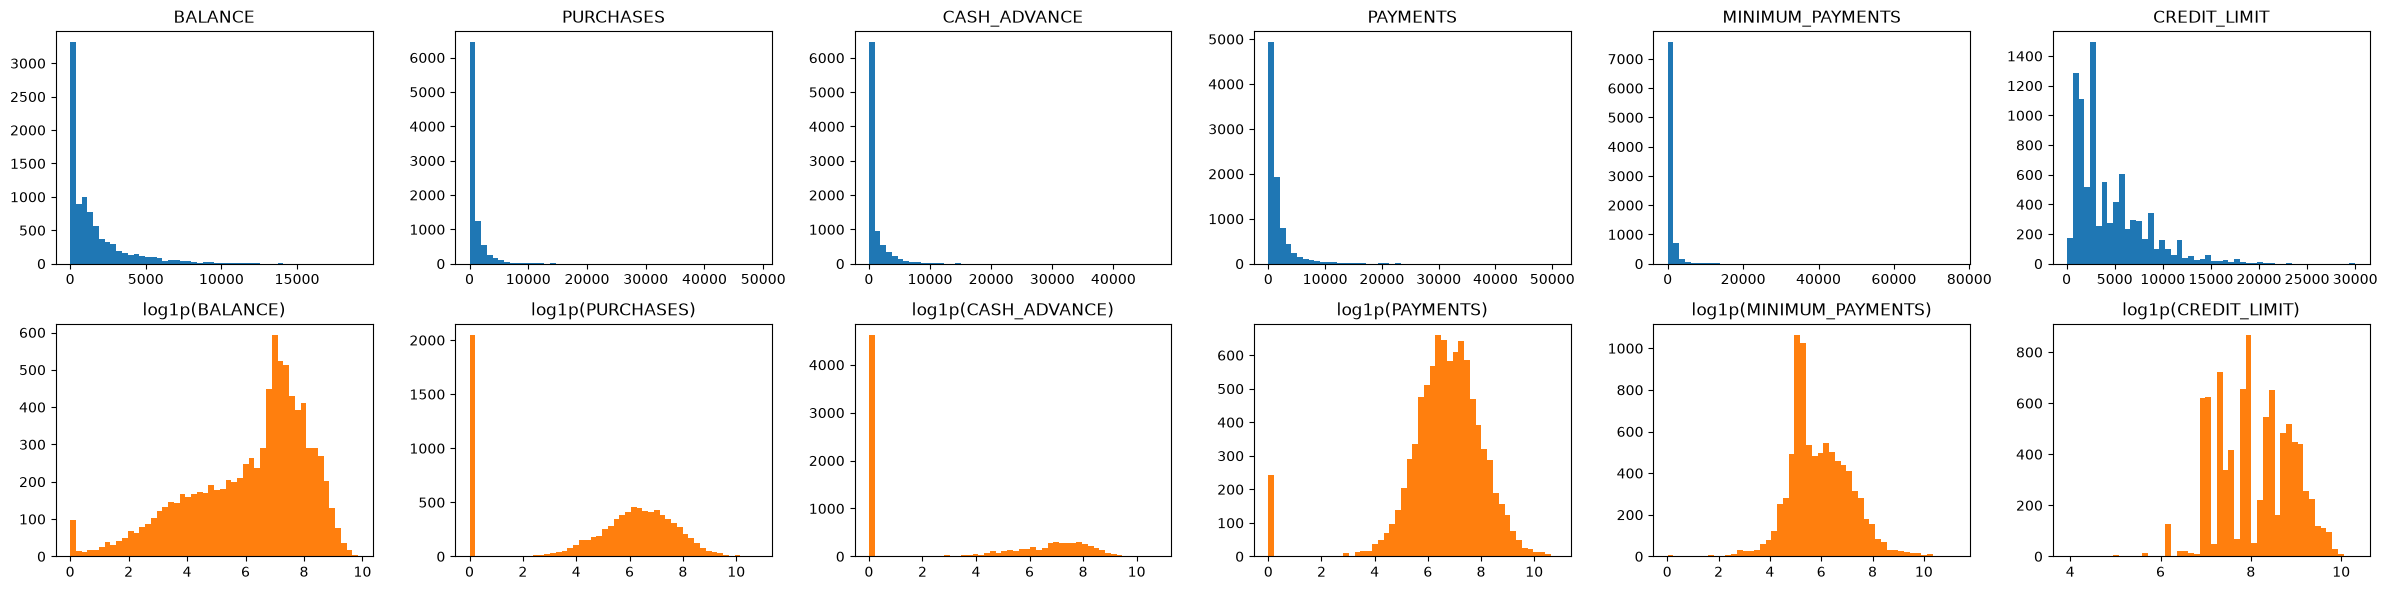

In [10]:
cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "PAYMENTS", "MINIMUM_PAYMENTS", "CREDIT_LIMIT"]
fig, axes = plt.subplots(2, len(cols), figsize=(4 * len(cols), 6))
for i, c in enumerate(cols):
    axes[0, i].hist(pdf[c].dropna(), bins=50); axes[0, i].set_title(c)
    axes[1, i].hist(np.log1p(pdf[c].dropna()), bins=50, color="C1"); axes[1, i].set_title(f"log1p({c})")
fig.tight_layout();
print("Skew original vs log1p:")
print(pd.DataFrame({"original": pdf[cols].skew(), "log1p": np.log1p(pdf[cols]).skew()}).round(2))

In [11]:
num = [c for c in VARIABLES]
resumen_atipicos(crudo, num)

,variable,lim_inf,lim_sup,n_bajo,n_alto,pct_atipicos,nota
0,BALANCE_FREQUENCY,0.722223,1.166666,1493,0,16.68,
1,PRC_FULL_PAYMENT,-0.214286,0.357143,0,1474,16.47,
2,CASH_ADVANCE,-1667.535000,2779.225000,0,1035,11.56,
3,ONEOFF_PURCHASES,-859.575000,1432.625000,0,1023,11.43,
4,ONEOFF_PURCHASES_FREQUENCY,-0.428571,0.714285,0,937,10.47,
5,INSTALLMENTS_PURCHASES,-700.080000,1166.800000,0,875,9.78,
6,MINIMUM_PAYMENTS,-805.586062,1794.179186,0,850,9.50,
7,PAYMENTS,-1888.215377,4169.495871,0,811,9.06,
8,PURCHASES,-1559.930000,2706.550000,0,810,9.05,
9,CASH_ADVANCE_TRX,-6.000000,10.000000,0,804,8.98,


,var_1,var_2,corr
14,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,0.983317
5,ONEOFF_PURCHASES,ONEOFF_PURCHASES_FREQUENCY,0.952011
10,CASH_ADVANCE,CASH_ADVANCE_TRX,0.951425
9,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,0.940214
7,INSTALLMENTS_PURCHASES,PURCHASES_INSTALLMENTS_FREQUENCY,0.921619
12,PURCHASES_FREQUENCY,PURCHASES_TRX,0.921069
0,BALANCE,MINIMUM_PAYMENTS,0.899789
4,PURCHASES,PURCHASES_TRX,0.885936
11,PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,0.853174
3,PURCHASES,PURCHASES_FREQUENCY,0.793824


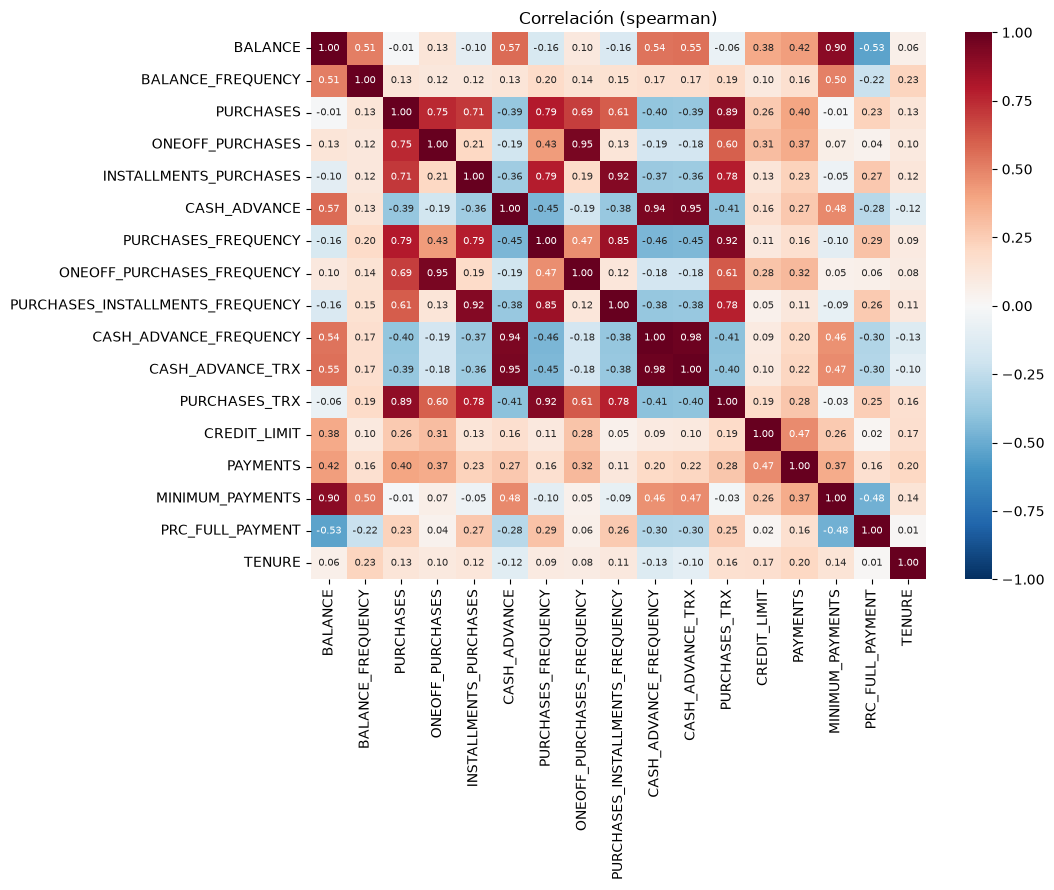

In [12]:
graficar_correlacion(crudo, num);
pares_correlacionados(crudo, num, umbral=0.7)

In [13]:
prep = preparar_features(crudo)
prep.select(*DERIVADAS).summary("mean", "50%", "max").toPandas()

,summary,UTILIZACION_LIMITE,RATIO_PAGO_MINIMO,COMPRA_PROMEDIO_TRX
0,mean,0.38892640897649133,9.350070123832555,73.87068309114211
1,50%,0.3025710953333334,2.1703569389305657,41.38
2,max,15.90995114,6840.5288605411015,5981.666666666667


In [14]:
spark.stop()

## Conclusiones del EDA
- **Calidad:** 8 950 clientes únicos, 17 variables numéricas, sin duplicados.
- **Nulos:** `MINIMUM_PAYMENTS` tiene 313 nulos; 240 (77 %) son clientes con `PAYMENTS = 0`, así que se imputan con 0. Los 73 restantes y el único nulo de `CREDIT_LIMIT` se imputan con la mediana de train.
- **Error de rango:** `CASH_ADVANCE_FREQUENCY` es una frecuencia (0 a 1), pero 8 clientes tienen valores hasta 1.5. Se recortan a 1.
- **Consistencia:** `PURCHASES` = `ONEOFF_PURCHASES` + `INSTALLMENTS_PURCHASES` en el 99.8 % de los casos: es una variable redundante.
- **Asimetría:** los montos tienen cola larga a la derecha (`MINIMUM_PAYMENTS` skew 13.6, `ONEOFF_PURCHASES` 10.1). Con `log1p` la asimetría baja a menos de 1 en la mayoría. Además, muchas variables tienen 22 % a 66 % de ceros, que se conservan como grupo ("no usa este producto").
- **`TENURE`:** el 85 % vale 12. Mide antigüedad, no comportamiento, y al estandarizar podría formar un cluster por sí sola. Se excluye del clustering y se usa solo en el perfilado.
- **Atípicos:** no se eliminan. Son clientes reales (por ejemplo, los grandes compradores son el segmento premium), y en producción todos deben recibir un segmento. Se usa `log1p` para que no dominen las distancias. La regla IQR marca como atípicos a variables acotadas (`BALANCE_FREQUENCY`, `PRC_FULL_PAYMENT`) que no lo son.
- **Correlación:** 15 pares superan 0.7 (avances en efectivo entre 0.94 y 0.98). En K-Means esos comportamientos contarían varias veces en la distancia, así que se aplica PCA.
- **Variables derivadas:** utilización del límite (riesgo; el 20 % usa más del 80 % del cupo), ratio pago / pago mínimo (revolvente vs transactor) y compra promedio (ticket). Describen cómo usa la tarjeta cada cliente, independientemente de su tamaño.